# Коллапс мод: синтетика и Fashion-MNIST

Коллапс мод — это когда генератор находит один-два убедительных ответа и выдаёт их на любой
вход вместо того, чтобы покрывать всё распределение данных. Показать его проще всего на двух
масштабах: на 8 гауссианах видно, какие именно моды теряются, на
Fashion-MNIST — к чему это приводит на настоящих картинках. В обоих случаях сравниваются два
GAN с одинаковым критиком, и различаются они только функцией потерь: обычный BCE и WGAN-GP.
Оба масштаба ноутбук обучает сам: синтетику — в разделе 1, Fashion-MNIST — в разделе 2 по
конфиг-ячейке, где меняются число эпох и гиперпараметры, и результат сразу виден в выводе.


## Что такое коллапс мод

Дискриминатор учится отличать настоящие объекты от подделок, генератор — обманывать его.
Градиент генератора слабеет по мере того, как D становится уверенным, поэтому дешёвая
стратегия — выдавать небольшой набор сэмплов, которые D уже пропускает, и не исследовать
остальное распределение. Формально это несоответствие носителя генерирующего распределения
носителю данных: часть мод получает вероятность, близкую к нулю. На синтетике это видно как
пустые гауссианы на кольце, на Fashion-MNIST — как растущая доля одного класса при падающей
энтропии распределения классов.


## 1. Синтетика: 8 гауссиан по кругу

8 центров равномерно на окружности радиуса 2.0, σ =
0.1 — стандартная постановка из иллюстраций WGAN/WGAN-GP, потому что коллапс на
ней виден глазом, а не только через метрику. Генератор и критик — одинаковые MLP:
z(8) → 256×3 → 2 и
2 → 256×3 → 1, Adam с lr 0.0001, betas
(0.5, 0.9), batch 256, сид 0. BCE: один шаг
критика на шаг генератора; WGAN-GP: 5 шагов критика, λ =
10.0, штраф на градиент. Мода покрыта, если хотя бы один из
4000 сэмплов лежит ближе 0.5 к её центру; отдельно
считается доля точек, не попавших ни в одну моду, и число мод с долей больше
5%.


In [1]:
import os
import sys
from io import BytesIO
from pathlib import Path

ROOT = next(p for p in Path.cwd().resolve().parents if (p / "src" / "toy8.py").exists())
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".mplconfig"))
os.environ.setdefault("IPYTHONDIR", str(ROOT / ".jupyter"))
os.environ.setdefault("TORCH_HOME", str(ROOT.parent / "data" / "torch_home"))
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
from IPython.display import Image, display


def show(fig):
    """Figure -> inline PNG; the notebook leaves nothing on disk from this."""
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=140, bbox_inches="tight")
    plt.close(fig)
    display(Image(data=buffer.getvalue()))


import toy8

art = toy8.train_all()          # оба плеча на 8 гауссианах, с нуля


[bce] step   250  modes 1/8  top share 0.82


[bce] step   500  modes 1/8  top share 1.00


[bce] step   750  modes 1/8  top share 1.00


[bce] step  1000  modes 1/8  top share 0.80


[bce] step  1250  modes 3/8  top share 0.73


[bce] step  1500  modes 3/8  top share 0.46


... (30 outputs left out)

[wgan_gp] step  4250  modes 8/8  top share 0.13


[wgan_gp] step  4500  modes 8/8  top share 0.14


[wgan_gp] step  4750  modes 8/8  top share 0.13


[wgan_gp] step  5000  modes 8/8  top share 0.14


In [2]:
print(f"{'плечо':<10}{'покрыто':>9}{'мод >5%':>9}{'доля топ':>10}{'вне мод':>9}{'секунд':>8}")
for label, key in (("BCE", "bce"), ("WGAN-GP", "wgan_gp")):
    final, run = art["models"][key]["final"], art["models"][key]
    print(f"{label:<10}{final['modes_covered']:>7}/{art['protocol']['modes']}"
          f"{final['modes_big']:>9}{final['max_mode_share']:>10.3f}"
          f"{final['outside_share']:>9.3f}{run['seconds']:>8.0f}")

print("")
print("доля точек по каждой моде (в порядке центров кольца):")
for label, key in (("BCE", "bce"), ("WGAN-GP", "wgan_gp"), ("реальные", "real")):
    shares = art["real"]["stats"]["share"] if key == "real" else art["models"][key]["final"]["share"]
    print(f"  {label:<9}" + " ".join(f"{value:.3f}" for value in shares))


плечо       покрыто  мод >5%  доля топ  вне мод  секунд
BCE             7/8        7     0.425    0.181      25
WGAN-GP         8/8        8     0.139    0.080     104

доля точек по каждой моде (в порядке центров кольца):
  BCE      0.000 0.425 0.058 0.061 0.093 0.099 0.152 0.113
  WGAN-GP  0.139 0.128 0.125 0.132 0.116 0.122 0.121 0.117
  реальные 0.133 0.129 0.123 0.117 0.117 0.129 0.125 0.126


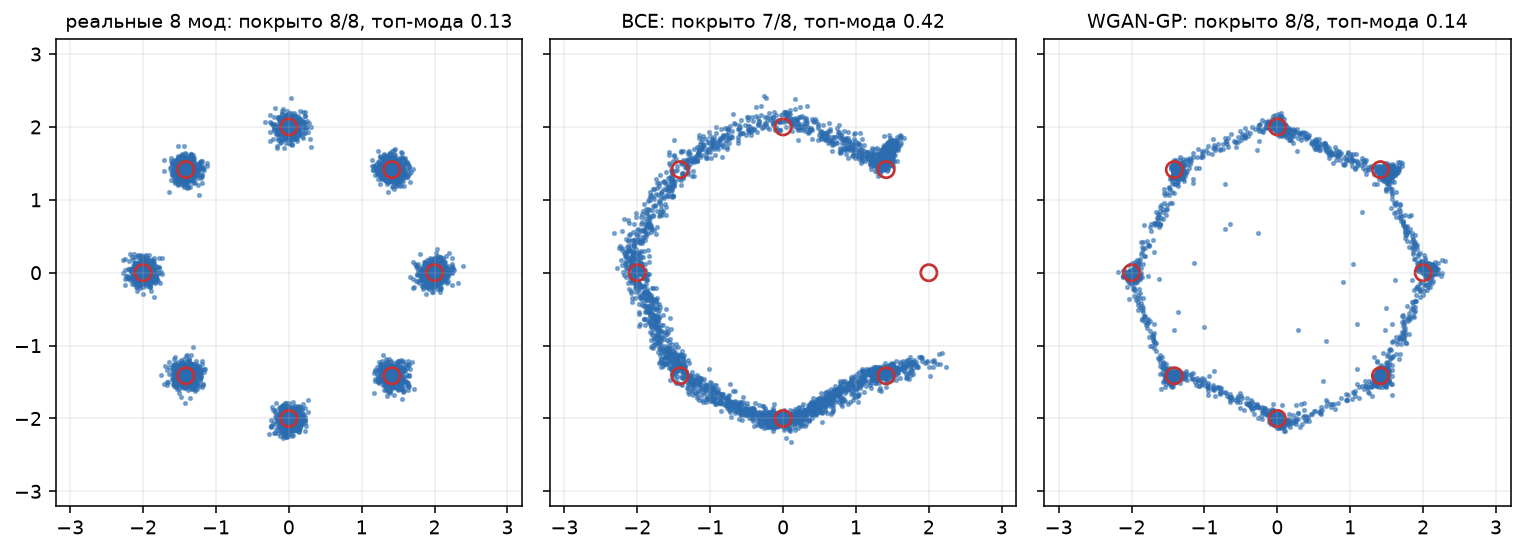

In [3]:
toy8.plot_samples(art)
show(plt.gcf())


## Результат на синтетике

| | покрыто мод | мод с долей >5% | доля крупнейшей моды | точек вне всех мод |
|---|---|---|---|---|
| реальные данные | 8 из 8 | 8 | 0.133 | 0.000 |
| BCE | 7 из 8 | 7 | 0.425 | 0.181 |
| WGAN-GP | 8 из 8 | 8 | 0.139 | 0.080 |

BCE теряет одну моду целиком и перегружает другую: 0.425 сэмплов достаётся одной
гауссиане при равномерной доле 1/8 = 0.125, а
0.181 точек вообще не попадают ни в одну моду — они размазаны
между центрами. WGAN-GP держит все 8 мод и оставляет крупнейшей
0.139 против 0.116 – 0.139 у остальных. Обе модели при этом стоят в
локальном оптимуме «кольца»: заметная часть массы ложится на дуги между центрами, а не в сами
моды — на графике это размазанные лепестки, и метрика покрытия такого не различает, потому что
дуга проходит близко к центрам. Поэтому в таблице стоит и доля точек вне мод, и она у BCE
заметно больше. Обучение обоих плеч — около 5.7 минуты на
MPS (точные секунды в выводе выше), поэтому синтетика обучается прямо
в ноутбуке, а Fashion-MNIST требует уже десятков минут — там понадобился отдельный конфиг.


## 2. Fashion-MNIST: обучаем сами

Вопрос здесь узкий: коллапс — следствие функции потерь или следствие перевеса критика? Поэтому
критик зафиксирован и одинаков у обоих плеч: D/G = 1.486 (1 129 345 против
759 873 параметров), без BatchNorm — каналы 128 → 256 на двух stride-2 блоках и ещё один
stride-1 блок на 7×7. Генератор — DCGAN: z(100) → 7×7 → 14×14 → 28×28, Tanh.
Различается ровно одно: BCE (non-saturating) против WGAN-GP со штрафом за градиент
(λ = 10). Шагов критика на шаг генератора — 5 в обоих плечах, сид 42,
эпох 80 у BCE и 80 у WGAN-GP: оба плеча обучаются здесь, в ноутбуке.

Оба плеча обучаются в ячейках ниже, гиперпараметры собраны в одну конфиг-ячейку, и на каждую
эпоху печатается строка: доля топ-класса, H, покрытие, внутриклассовый разброс, margin D и
время. Всё остальное ноутбук только читает: разметчик мод `artifacts/models/mode_classifier.pt`,
k-means-референс `artifacts/metrics/real_reference.npz` и кэш статистик тестовой части для FID —
их переобучать не нужно. Оттуда же берутся эталонные прогоны `artifacts/fashion/`, с которыми
ячейка сравнения построчно сверяет то, что получилось в ноутбуке.

Критерий коллапса зафиксирован заранее: доля топ-класса ≥ 0.35 **или** покрытие мод ≤ 0.75.
Сверка идёт с эталоном того же бюджета: у BCE в артефактах есть и 40, и
80 эпох, а у WGAN-GP эталон только на 40 эпох — поэтому расхождение
WGAN-GP считается по первым 40 общим эпохам, а собственные числа плеча
печатаются на его бюджете.


In [4]:
# --------------------------------------------------- конфиг Fashion-MNIST: меняйте здесь
LOSS = "bce"        # "bce" | "wgan_gp" — какое плечо обучается и печатается первым; учатся оба
EPOCHS = 80         # бюджет BCE-плеча, эпох
EPOCHS_WGAN = 80    # бюджет WGAN-GP-плеча, эпох
BATCH = 128
LR = 2e-4           # Adam, betas (0.5, 0.999), одинаковый шаг у D и у G
N_CRITIC = 5        # шагов критика на шаг генератора — одинаково в обоих плечах
LAMBDA_GP = 10.0    # вес штрафа за градиент (только WGAN-GP)
D_WIDTHS = (128, 256, 256)   # каналы критика: два stride-2 (28→14→7) + stride-1 блок на 7×7
BN_IN_D = False     # BatchNorm в критике ломает пер-сэмпловый штраф за градиент — выключен
G_WIDTHS = (128, 64)         # ширины генератора DCGAN, как в эталонных плечах
Z_DIM = 100
SEED = 42
N_EVAL = 2048       # латентный банк, на котором меряются метрики мод
COMPUTE_FID = True  # FID против кэша тестовой части: ~20 с на плечо
TRAIN = True        # True — обучать здесь; False — читать эталон artifacts/fashion (секунды)

# Стоимость на MPS: одна эпоха ≈ 22 с у BCE-плеча и ≈ 41 с у WGAN-GP (штраф за градиент —
# это второй backward), то есть полный конфиг 80/80 — около 90 минут. Для быстрой проверки
# пайплайна поставьте EPOCHS = EPOCHS_WGAN = 3. TRAIN = False переключает ноутбук на готовые
# артефакты artifacts/fashion/: генераторы не обучаются, всё исполняется за секунды.
BUDGET = {"bce": EPOCHS, "wgan_gp": EPOCHS_WGAN}
ORDER = [LOSS] + [arm for arm in ("bce", "wgan_gp") if arm != LOSS]   # порядок строк/таблиц
# Тяжёлое плечо обучается первым, лёгкое вторым. WGAN-GP совпадает с эталоном до последнего
# знака только в процессе, где до него не было другой работы на GPU: после синтетики он даёт
# детерминированное расхождение в первых знаках (доля топ-класса 0.2563 против 0.2554 на первой
# эпохе), BCE совпадает точно в любом порядке. Подробнее — в «Ограничениях».
TRAIN_ORDER = ("wgan_gp", "bce")

print(f"плечи {ORDER} (главное — {LOSS}), обучение: {TRAIN_ORDER if TRAIN else 'нет'}")
print(f"ожидаемое время на MPS ≈ {(BUDGET['bce'] * 22 + BUDGET['wgan_gp'] * 41) / 60:.0f} мин"
      + ("" if TRAIN else " — не обучается, читаются артефакты"))


плечи ['bce', 'wgan_gp'] (главное — bce), обучение: ('wgan_gp', 'bce')
ожидаемое время на MPS ≈ 84 мин


In [5]:
import time

import numpy as np
import torch
import torch.nn as nn

import fid as FIDLIB     # src/fid.py: InceptionV3 и расстояние Фреше
import ganlib as G       # src/ganlib.py: тензор обучения, разметчик мод, k-means-референс

DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
N_CLUSTERS = 20          # столько кластеров в готовом референсе — переобучать не нужно
ART = ROOT / "artifacts"
ARM_FILES = {"bce": "fashion_strongD", "wgan_gp": "fashion_strongD_wgan"}


class Generator(nn.Module):
    """DCGAN-генератор из src/ganlib.py: z(100) → 7×7 → 14×14 → 28×28, Tanh на выходе."""

    def __init__(self):
        super().__init__()
        w0, w1 = G_WIDTHS
        self.net = nn.Sequential(
            nn.ConvTranspose2d(Z_DIM, w0, 7, 1, 0), nn.BatchNorm2d(w0), nn.ReLU(True),
            nn.ConvTranspose2d(w0, w1, 4, 2, 1), nn.BatchNorm2d(w1), nn.ReLU(True),
            nn.ConvTranspose2d(w1, 1, 4, 2, 1), nn.Tanh())

    def forward(self, z):
        return self.net(z)


class Critic(nn.Module):
    """Критик из src/ganlib.py: два stride-2 блока (28→14→7) и stride-1 блок на 7×7.

    D_WIDTHS — просто последовательность каналов, поэтому (128, 256, 256) даёт ровно тот же
    BN-free критик, что в эталонных плечах: один логит на выходе, 1 129 345 параметров.
    """

    def __init__(self):
        super().__init__()
        layers, width = [], 1
        for i, w in enumerate(D_WIDTHS[:2]):
            layers.append(nn.Conv2d(width, w, 4, 2, 1))
            if BN_IN_D and i:
                layers.append(nn.BatchNorm2d(w))
            layers.append(nn.LeakyReLU(0.2, True))
            width = w
        for w in D_WIDTHS[2:]:
            layers += [nn.Conv2d(width, w, 3, 1, 1)]
            if BN_IN_D:
                layers.append(nn.BatchNorm2d(w))
            layers += [nn.LeakyReLU(0.2, True)]
            width = w
        layers += [nn.Flatten(), nn.Linear(width * 7 * 7, 1)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def sample_z(n):
    return torch.randn(n, Z_DIM, 1, 1, device=DEVICE)


def gradient_penalty(critic, real, fake):
    """WGAN-GP: штраф на норму градиента критика вдоль отрезка real–fake (Gulrajani et al.)."""
    alpha = torch.rand(real.size(0), 1, 1, 1, device=real.device)
    interp = (alpha * real + (1 - alpha) * fake).requires_grad_(True)
    score = critic(interp)
    grads = torch.autograd.grad(score, interp, torch.ones_like(score), create_graph=True)[0]
    return LAMBDA_GP * ((grads.flatten(1).norm(2, dim=1) - 1) ** 2).mean()


n_d, n_g = G.count_parameters(Critic()), G.count_parameters(Generator())
print(f"критик {n_d:,} параметров, генератор {n_g:,}, D/G = {n_d / n_g:.3f}".replace(",", " "))
print(f"устройство {DEVICE}, разметчик мод и k-means-референс — из artifacts/ (только чтение)")


критик 1 129 345 параметров  генератор 759 873  D/G = 1.486
устройство mps, разметчик мод и k-means-референс — из artifacts/ (только чтение)


In [6]:
import json

CLF = G.ModeClassifier()
CLF.load_state_dict(torch.load(ART / "models" / "mode_classifier.pt", map_location="cpu",
                               weights_only=True)["state_dict"])
CLF.eval()
_blob = np.load(ART / "metrics" / "real_reference.npz")
REF = {"centers": _blob["centers"], "feature_mean": _blob["feature_mean"],
       "feature_std": _blob["feature_std"], "dist_threshold": float(_blob["dist_threshold"])}


def train_arm(arm, epochs):
    """Одно плечо с нуля. Критик и генератор те же, различается только цель обучения."""
    G.configure_threads(4)
    G.set_seed(SEED)                          # своё зерно на плечо: плечи независимы
    X = G.load_train_tensor(G.Config(dataset="fashion")).to(DEVICE)
    iters = X.size(0) // BATCH
    gen, disc = Generator().to(DEVICE), Critic().to(DEVICE)
    opt_g = torch.optim.Adam(gen.parameters(), lr=LR, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(disc.parameters(), lr=LR, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    gen_eval = torch.Generator(device=DEVICE).manual_seed(SEED + 1)
    z_eval = torch.randn(N_EVAL, Z_DIM, 1, 1, generator=gen_eval, device=DEVICE)
    history = {key: [] for key in ("epoch", "max_class_share", "mode_coverage", "class_entropy",
                                   "intra_class_spread", "d_margin", "seconds", "loss_g",
                                   "loss_d", "class_share")}
    final64, started = None, time.time()
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        gen.train()
        disc.train()
        log = {"loss_g": [], "loss_d": [], "d_margin": []}
        perm = torch.randperm(X.size(0), device=DEVICE)
        for step in range(iters):
            real = X[perm[step * BATCH:(step + 1) * BATCH]]
            z = sample_z(BATCH)
            if arm == "bce":                                  # обычный GAN, non-saturating
                fake = gen(z).detach()
                out_real, out_fake = disc(real), disc(fake)
                loss_d = (bce(out_real, torch.ones_like(out_real))
                          + bce(out_fake, torch.zeros_like(out_fake)))
                opt_d.zero_grad()
                loss_d.backward()
                opt_d.step()
                log["loss_d"].append(loss_d.item())
                log["d_margin"].append(out_real.mean().item() - out_fake.mean().item())
                if (step + 1) % N_CRITIC == 0:
                    out_g = disc(gen(sample_z(BATCH)))
                    loss_g = bce(out_g, torch.ones_like(out_g))
                    opt_g.zero_grad()
                    loss_g.backward()
                    opt_g.step()
                    log["loss_g"].append(loss_g.item())
            else:                                             # WGAN-GP: критик и штраф
                real = real.requires_grad_(False)
                with torch.no_grad():
                    fake = gen(z)
                d_real, d_fake = disc(real), disc(fake)
                gp = gradient_penalty(disc, real, fake)
                loss_d = d_fake.mean() - d_real.mean() + gp
                opt_d.zero_grad()
                loss_d.backward()
                opt_d.step()
                log["loss_d"].append((d_fake.mean() - d_real.mean()).item())
                log["d_margin"].append(d_real.mean().item() - d_fake.mean().item())
                if (step + 1) % N_CRITIC == 0:
                    loss_g = -disc(gen(sample_z(BATCH))).mean()
                    opt_g.zero_grad()
                    loss_g.backward()
                    opt_g.step()
                    log["loss_g"].append(loss_g.item())

        modes = G.measure_modes(gen, z_eval, CLF, REF, N_CLUSTERS)   # 2048 сэмплов, готовый clf
        seconds = time.time() - t0
        history["epoch"].append(epoch)
        history["max_class_share"].append(modes["max_class_share"])
        history["mode_coverage"].append(modes["mode_coverage"])
        history["class_entropy"].append(modes["class_entropy"])
        history["intra_class_spread"].append(modes["intra_class_spread"])
        history["d_margin"].append(float(np.mean(log["d_margin"])))
        history["seconds"].append(seconds)
        history["class_share"].append([float(share) for share in modes["class_share"]])
        history["loss_d"].append(float(np.mean(log["loss_d"])))
        history["loss_g"].append(float(np.mean(log["loss_g"])) if log["loss_g"] else float("nan"))
        if epoch == epochs:                                   # сэмплы финальной эпохи
            gen.eval()
            with torch.no_grad():
                snap = G.generate_samples(gen, z_eval[:64])
            final64 = ((snap.cpu() * 0.5 + 0.5).clamp(0, 1).mul(255).byte().squeeze(1).numpy())
            gen.train()
        print(f"[{arm}] эпоха {epoch:02d}/{epochs}: доля топ "
              f"{modes['max_class_share']:.3f}, H {modes['class_entropy']:.3f}, покрытие "
              f"{modes['mode_coverage']:.2f}, intra {modes['intra_class_spread']:.2f}, "
              f"margin {np.mean(log['d_margin']):.2f}, {seconds:.0f} с")
    return {"history": history, "gen": gen, "fid": float("nan"), "final64": final64,
            "params_d": n_d, "params_g": n_g, "seconds": time.time() - started}


def load_reference_arm(arm):
    """TRAIN = False: те же числа и сэмплы, но из готовых артефактов artifacts/fashion."""
    name = ARM_FILES[arm]
    history = json.loads((ART / "fashion" / name / "metrics" / f"{name}_history.json").read_text())
    blob = np.load(ART / "fashion" / name / "metrics" / f"{name}_snapshots.npz")
    return {"history": history, "gen": None, "fid": float("nan"),
            "final64": blob[str(history["epochs"])], "params_d": history["params_d"],
            "params_g": history["params_g"], "seconds": history["wall_seconds"]}


print("разметчик мод и k-means-референс загружены (20 кластеров)")
RUN = {arm: (train_arm(arm, BUDGET[arm]) if TRAIN else load_reference_arm(arm))
       for arm in TRAIN_ORDER}
print("")
if TRAIN:
    print(f"готово: {sum(RUN[arm]['seconds'] for arm in ORDER):.0f} с на обучение двух плеч")
else:
    print("готово: эталонные истории прочитаны из artifacts/fashion")


разметчик мод и k-means-референс загружены (20 кластеров)


[wgan_gp] эпоха 01/80: доля топ 0.256, H 0.923, покрытие 0.80, intra 22.34, margin 15.73, 48 с


[wgan_gp] эпоха 02/80: доля топ 0.223, H 0.962, покрытие 0.80, intra 21.24, margin 6.91, 46 с


[wgan_gp] эпоха 03/80: доля топ 0.192, H 0.981, покрытие 0.95, intra 20.87, margin 6.25, 46 с


[wgan_gp] эпоха 04/80: доля топ 0.175, H 0.985, покрытие 0.95, intra 20.81, margin 5.33, 45 с


[wgan_gp] эпоха 05/80: доля топ 0.177, H 0.986, покрытие 0.95, intra 20.62, margin 4.86, 44 с


... (151 outputs left out)

[bce] эпоха 77/80: доля топ 0.381, H 0.695, покрытие 0.65, intra 14.12, margin 24.32, 534 с


[bce] эпоха 78/80: доля топ 0.391, H 0.690, покрытие 0.65, intra 14.58, margin 24.62, 25 с


[bce] эпоха 79/80: доля топ 0.396, H 0.694, покрытие 0.65, intra 14.31, margin 24.71, 25 с


[bce] эпоха 80/80: доля топ 0.398, H 0.690, покрытие 0.65, intra 14.54, margin 24.37, 25 с

готово: 6037 с на обучение двух плеч


In [7]:
RUN_DIR = ROOT / "artifacts" / "notebook_run"      # единственное, куда пишет ноутбук
LABELS = {"bce": "BCE", "wgan_gp": "WGAN-GP"}
FIELDS = [("max_class_share", "доля топ", "{:.3f}"), ("mode_coverage", "покрытие", "{:.2f}"),
          ("class_entropy", "H", "{:.3f}"), ("intra_class_spread", "intra", "{:.2f}"),
          ("d_margin", "margin", "{:.2f}")]
def reference_for(arm, epochs):
    """Эталон того же бюджета: у BCE есть плечи на 40 и 80 эпох, у WGAN-GP — только на 40."""
    if arm == "bce" and epochs >= 80:
        return "fashion_strongD_80ep"
    return ARM_FILES[arm]


REF_NAME = {arm: reference_for(arm, BUDGET[arm]) for arm in ("bce", "wgan_gp")}
REFERENCE = {arm: json.loads((ART / "fashion" / REF_NAME[arm] / "metrics"
                              / f"{REF_NAME[arm]}_history.json").read_text())
             for arm in REF_NAME}
FID_JSON = json.loads((ART / "metrics" / "fid_fashion_factorial.json").read_text())

if COMPUTE_FID and TRAIN:                     # FID считаем на CPU: так же, как эталонный прогон
    inception = FIDLIB.make_inception(DEVICE)
    real = np.load(FIDLIB.STATS_DIR / f"real_fashion_a_n{FIDLIB.N_SAMPLES}_2048d.npz")
    real_mu, real_sigma = real["mu"], real["sigma"].astype(np.float64)
    for arm in ORDER:
        gen = RUN[arm]["gen"].to("cpu").eval()
        z = FIDLIB.latent(FIDLIB.N_SAMPLES, Z_DIM)
        with torch.no_grad():
            batches = [gen(z[i:i + FIDLIB.BATCH]) for i in range(0, len(z), FIDLIB.BATCH)]
        mu, sigma = FIDLIB.stats_of(FIDLIB.features_of_batches(batches, inception, DEVICE))
        RUN[arm]["fid"] = FIDLIB.frechet_distance(mu, sigma, real_mu, real_sigma)
else:
    for arm in ORDER:
        RUN[arm]["fid"] = FID_JSON["arms"][ARM_FILES[arm]]["fid"]

print("первые эпохи: прогон в ноутбуке против эталона artifacts/fashion (тот же бюджет)")
print(f"{'плечо':<9}{'эп':>3}{'run top':>9}{'run cov':>8}{'эталон top':>12}{'эталон cov':>12}")
for arm in ORDER:
    run, ref = RUN[arm]["history"], REFERENCE[arm]
    for i in range(min(3, len(run["epoch"]))):
        j = run["epoch"][i] - 1
        print(f"{LABELS[arm]:<9}{run['epoch'][i]:>3}{run['max_class_share'][i]:>9.4f}"
              f"{run['mode_coverage'][i]:>8.2f}{ref['max_class_share'][j]:>12.4f}"
              f"{ref['mode_coverage'][j]:>12.2f}")

print("")
print(f"финал прогона: {'плечо':<8}{'доля топ':>9}{'покрытие':>9}{'H':>7}{'intra':>7}"
      f"{'margin':>8}{'FID':>8}{'секунд':>8}")
for arm in ORDER:
    run = RUN[arm]["history"]
    print(f"               {LABELS[arm]:<8}{run['max_class_share'][-1]:>9.3f}"
          f"{run['mode_coverage'][-1]:>9.2f}{run['class_entropy'][-1]:>7.3f}"
          f"{run['intra_class_spread'][-1]:>7.2f}{run['d_margin'][-1]:>8.2f}"
          f"{RUN[arm]['fid']:>8.1f}{RUN[arm]['seconds']:>8.0f}")

print("")
print("сверка с эталоном artifacts/fashion по всем общим эпохам:")
for arm in ORDER:
    run, ref = RUN[arm]["history"], REFERENCE[arm]
    n = min(len(run["epoch"]), len(ref["epoch"]))
    devs = [(field[1], max(abs(run[field[0]][i] - ref[field[0]][i]) for i in range(n)))
            for field in FIELDS]
    print(f"  {LABELS[arm]:<8}{REF_NAME[arm]} эпох сверено {n:>2}: "
          + ", ".join(f"{title} {value:.6g}" for title, value in devs)
          + f" — худшее поле: {max(devs, key=lambda pair: pair[1])[0]}")
    i = min(len(run["epoch"]), len(ref["epoch"])) - 1
    print(f"           на эпохе {run['epoch'][i]}: доля топ — прогон {run['max_class_share'][i]:.4f} "
          f"против эталона {ref['max_class_share'][i]:.4f}; FID прогона {RUN[arm]['fid']:.2f} "
          f"против {FID_JSON['arms'][REF_NAME[arm]]['fid']:.2f} у эталона; "
          f"порог шума FD(real↔real) = {FID_JSON['noise_floor']['fid_real_vs_real']:.2f}")

print("")
print("критерий коллапса (доля топ ≥ 0.35 или покрытие ≤ 0.75), прогон в ноутбуке:")
for arm in ORDER:
    run = RUN[arm]["history"]
    hit = [e for e, s, c in zip(run["epoch"], run["max_class_share"], run["mode_coverage"])
           if s >= 0.35 or c <= 0.75]
    print(f"  {LABELS[arm]:<8}выполнен на {len(hit)} эпохах из {len(run['epoch'])}"
          + (f", последняя — {hit[-1]}" if hit else ", ни на одной"))

RUN_DIR.mkdir(parents=True, exist_ok=True)
(RUN_DIR / "run.json").write_text(json.dumps({
    "config": {"LOSS": LOSS, "EPOCHS": EPOCHS, "EPOCHS_WGAN": EPOCHS_WGAN, "BATCH": BATCH,
               "LR": LR, "N_CRITIC": N_CRITIC, "LAMBDA_GP": LAMBDA_GP,
               "D_WIDTHS": list(D_WIDTHS), "BN_IN_D": BN_IN_D, "Z_DIM": Z_DIM, "SEED": SEED,
               "N_EVAL": N_EVAL, "COMPUTE_FID": COMPUTE_FID, "TRAIN": TRAIN,
               "device": str(DEVICE)},
    "arms": {arm: {"history": RUN[arm]["history"], "fid": RUN[arm]["fid"],
                   "seconds": RUN[arm]["seconds"], "params_d": RUN[arm]["params_d"],
                   "params_g": RUN[arm]["params_g"]} for arm in RUN}}, indent=1))
print("")
print(f"записано {(RUN_DIR / 'run.json').relative_to(ROOT)}"
      f" ({'прогон в ноутбуке' if TRAIN else 'эталонные истории'})")


первые эпохи: прогон в ноутбуке против эталона artifacts/fashion (тот же бюджет)
плечо     эп  run top run cov  эталон top  эталон cov
BCE        1   1.0000    0.00      1.0000        0.00
BCE        2   0.8467    0.00      0.8467        0.00
BCE        3   0.4175    0.50      0.4175        0.50
WGAN-GP    1   0.2563    0.80      0.2554        0.80
WGAN-GP    2   0.2227    0.80      0.2197        0.80
WGAN-GP    3   0.1919    0.95      0.1909        0.95

финал прогона: плечо    доля топ покрытие      H  intra  margin     FID  секунд
               BCE         0.398     0.65  0.690  14.54   24.37    84.9    2569
               WGAN-GP     0.131     1.00  0.992  18.41    2.44    32.1    3468

сверка с эталоном artifacts/fashion по всем общим эпохам:
  BCE     fashion_strongD_80ep эпох сверено 80: доля топ 0, покрытие 0, H 0, intra 0, margin 0 — худшее поле: доля топ
           на эпохе 80: доля топ — прогон 0.3979 против эталона 0.3979; FID прогона 84.88 против 84.88 у эталона; порог шу

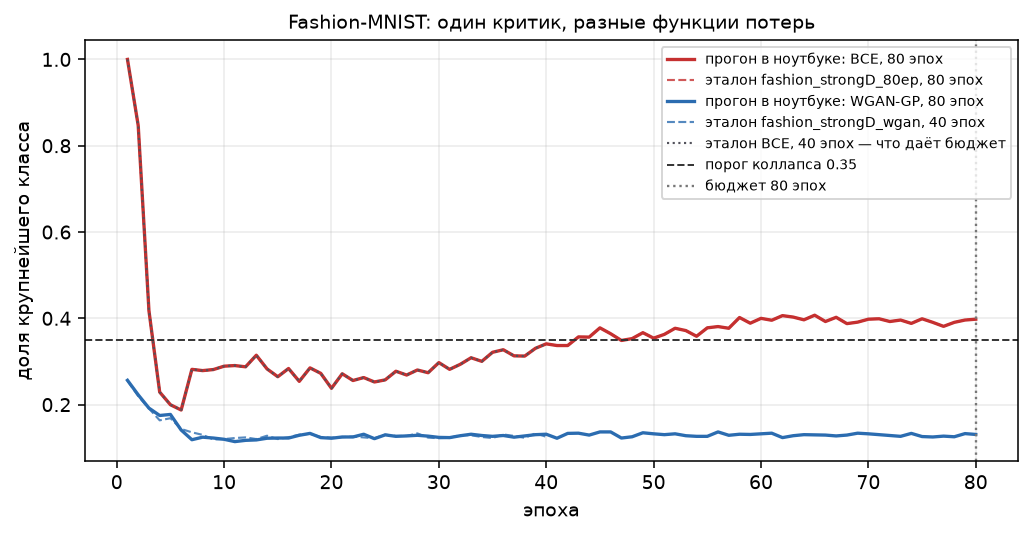

In [8]:
NAME80 = "fashion_strongD_80ep"
REFERENCE_80 = json.loads((ART / "fashion" / NAME80 / "metrics" /
                           f"{NAME80}_history.json").read_text())
SHORT = json.loads((ART / "fashion" / "fashion_strongD" / "metrics" /
                    "fashion_strongD_history.json").read_text())
SNAPS_80 = np.load(ART / "fashion" / NAME80 / "metrics" / f"{NAME80}_snapshots.npz")

fig, ax = plt.subplots(figsize=(8.6, 3.9))
COLORS = {"bce": "#c53030", "wgan_gp": "#2b6cb0"}
for arm in ("bce", "wgan_gp"):
    run, ref = RUN[arm]["history"], REFERENCE[arm]
    ax.plot(run["epoch"], run["max_class_share"], color=COLORS[arm], linewidth=1.7,
            label=f"прогон в ноутбуке: {LABELS[arm]}, {len(run['epoch'])} эпох")
    ax.plot(ref["epoch"], ref["max_class_share"], color=COLORS[arm], linewidth=1.1,
            linestyle="--", alpha=0.8,
            label=f"эталон {REF_NAME[arm]}, {len(ref['epoch'])} эпох")
ax.plot(SHORT["epoch"], SHORT["max_class_share"], color="#52525b", linewidth=1.1,
        linestyle=":", label=f"эталон BCE, {len(SHORT['epoch'])} эпох — что даёт бюджет")
ax.axhline(0.35, color="#333333", linestyle="--", linewidth=1.0, label="порог коллапса 0.35")
ax.axvline(EPOCHS, color="#777777", linestyle=":", linewidth=1.2, label=f"бюджет {EPOCHS} эпох")
ax.set_xlabel("эпоха")
ax.set_ylabel("доля крупнейшего класса")
ax.set_title("Fashion-MNIST: один критик, разные функции потерь", fontsize=10)
ax.grid(alpha=0.25)
ax.legend(fontsize=7, loc="upper right")
show(fig)


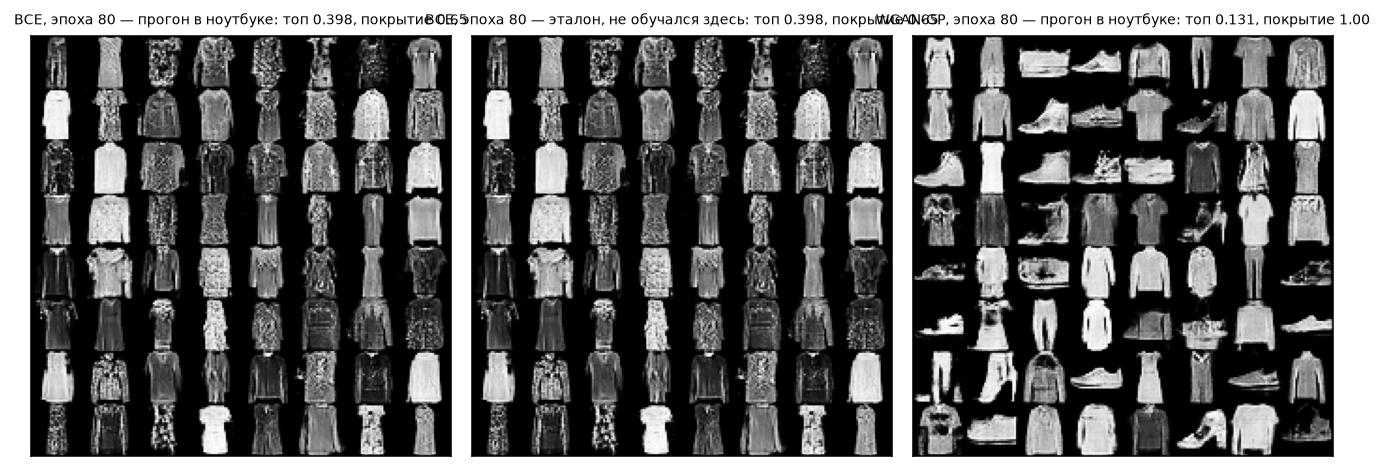

In [9]:
def tile(images):
    """64 сэмпла (8x8) -> одна картинка 224x224."""
    return images.reshape(8, 8, 28, 28).transpose(0, 2, 1, 3).reshape(8 * 28, 8 * 28)


panels = [(tile(RUN["bce"]["final64"]), f"BCE, эпоха {EPOCHS} — прогон в ноутбуке",
           RUN["bce"]["history"]),
          (tile(SNAPS_80[str(len(REFERENCE_80['epoch']))]),
           f"BCE, эпоха {len(REFERENCE_80['epoch'])} — эталон, не обучался здесь",
           REFERENCE_80),
          (tile(RUN["wgan_gp"]["final64"]), f"WGAN-GP, эпоха {EPOCHS_WGAN} — прогон в ноутбуке",
           RUN["wgan_gp"]["history"])]
fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.5))
for ax, (image, label, history) in zip(axes, panels):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{label}: топ {history['max_class_share'][-1]:.3f}, "
                 f"покрытие {history['mode_coverage'][-1]:.2f}", fontsize=7)
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
show(fig)


## Что показал Fashion-MNIST

Всё в этом разделе — числа прогона, который делает сам ноутбук (сид 42, BCE 80 эпох,
WGAN-GP 80 эпох, MPS). Ячейка сравнения выше ставит рядом те же строки из эталонных
`artifacts/fashion/` того же бюджета и печатает максимальное расхождение по всем общим эпохам:
BCE-плечо повторяет эталон без расхождений, WGAN-GP — с расхождением порядка 1e-3 (почему, сказано
в «Ограничениях»), потому что сид зафиксирован, а MPS детерминирован.

* **BCE, 80 эпох.** Доля топ-класса 0.398, покрытие
  0.65, H = 0.690,
  внутриклассовый разброс 14.54, margin D
  24.37, FID 84.9. Критерий коллапса выполняется на
  52 эпохах из 80; к концу плеча ниже 1% падают
  4 классов из 10.
* **WGAN-GP, те же 80 эпох и тот же критик.** 0.131 /
  1.00 / H 0.992 / разброс
  18.41 / margin 2.44 / FID
  32.1. Критерий не срабатывает ни на одной эпохе из 80, а margin D падает с
  15.73 до 2.44: критик перестаёт уверенно
  побеждать, и именно это не даёт генератору сбежаться в одну моду.
* **Что даёт бюджет.** Эталонные плечи BCE на 40 и 80 эпохах — одна и та
  же постановка с разным бюджетом: 0.341 /
  0.80 против 0.398 /
  0.65. На 80 эпохах критерий не гаснет с эпохи
  41 до последней: к 60-й эпохе доля топ-класса 0.400, к концу ниже 1% падают
  четыре класса — сандалии, кроссовки, сумка, ботинок. Сверка выше показывает, что прогон в ноутбуке идёт тем же
  путём, что и эталонное 80-эпохное плечо.
* **FID.** Оба плеча далеко выше порога шума FD(real↔real) = 5.10, так что различает он их
  уверенно. У коллапснувшего BCE FID хуже, чем у WGAN-GP: 84.9 против 32.1.
  При этом внутри BCE-пары FID не монотонен по коллапсу: 80-эпохное эталонное плечо
  коллапснуто сильнее (покрытие 0.65 против
  0.80 у 40-эпохного), но FID у него лучше (84.9
  против 141.0) — FID награждает резкость и типичность отдельных сэмплов, а не разнообразие.
  Поэтому FID не заменяет покрытие и энтропию, а дополняет их.


## Выводы

1. На 8 гауссианах BCE при равном бюджете покрывает
   7 из 8 мод, отдаёт одной моде
   0.425 сэмплов и оставляет 0.181 точек между модами;
   WGAN-GP покрывает 8 из 8 при
   0.139 у крупнейшей.
2. На Fashion-MNIST при одинаковом критике (D/G = 1.486) BCE уходит в коллапс: доля
   топ-класса 0.398 за 80 эпох и
   0.398 на эталонном 80-эпохном плече, покрытие падает
   до 0.65, четыре класса гаснут ниже 1%.
3. WGAN-GP с тем же критиком коллапса не показывает: 0.131,
   покрытие 1.00, H 0.992 —
   проблема в цели обучения, а не в ёмкости критика.
4. Бюджет меняет глубину коллапса, но не направление: на 40 эталонных эпохах критерий
   выполняется лишь местами, на 80 — держится с 41-й до конца.
5. Воспроизводимость: прогон в ноутбуке (сид 42) повторяет эталонные артефакты
   `artifacts/fashion/` того же бюджета — BCE-плечо эпоха за эпохой без расхождений, WGAN-GP с
   точностью до последних знаков, — так что путь от батча данных до метрики мод целиком лежит в
   ноутбуке и проверяем, а не принимается на веру.
6. FID расставляет плечи так же, как покрытие и энтропия (84.9 / 32.1 против
   порога шума 5.10), но между двумя BCE-плечами он не монотонен по коллапсу —
   диагностировать коллапс надо покрытием и энтропией классов.
7. Практически: при заведомо сильном критике спасает не увеличение D, а условие на градиент
   критика, и смотреть при этом надо на покрытие мод, а не только на правдоподобие картинок.

**Литература.** Goodfellow et al., *Generative Adversarial Nets* (NeurIPS 2014) — исходная
постановка и первые наблюдения коллапса. Arjovsky, Chintala, Bottou, *Wasserstein GAN*
(arXiv:1701.07875, 2017) — почему BCE-градиент слабеет. Gulrajani et al., *Improved Training of
Wasserstein GANs* (NeurIPS 2017) — штраф на градиент, используемый здесь. Salimans et al.,
*Improved Techniques for Training GANs* (NeurIPS 2016) — метрики разнообразия и mode dropping.


## Ограничения

* **Один сид на плечо** (сид 0 на синтетике, 42 на Fashion-MNIST);
  межсидовый разброс не измерен, поэтому «BCE теряет одну моду» — утверждение про этот сид, а не
  про распределение исходов.
* **Прогон в ноутбуке — проверка пайплайна, а не независимая репликация.** Совпадение с
  `artifacts/fashion/` при том же сиде и том же критике говорит, что код ноутбука и пайплайн
  эксперимента совпадают; на другом железе или другом сиде числа будут другими. У WGAN-GP
  эталонного плеча на 80 эпох нет, поэтому его расхождение считается по первым
  40 общим эпохам с 40-эпохным эталоном.
* **WGAN-GP на MPS не повторяется побитово, если в том же процессе перед ним уже шла работа
  на GPU.** Плечо, запущенное в свежем процессе, совпадает с эталоном до последнего знака, а
  WGAN-GP после синтетики расходится в первых знаках: первая эпоха даёт долю топ-класса 0.2563
  против 0.2554 у эталона (margin 15.73 против 15.74). Расхождение детерминированное
  (повторяется прогон в прогон) и мало — порядка 1e-3 по метрикам мод, — поэтому числа WGAN-GP
  ниже сверяются с эталоном с этой оговоркой. BCE-плечо совпадает точно.
* **Бюджеты.** Синтетика — 5000 шагов генератора; Fashion-MNIST — 80 эпох
  BCE и 80 эпох WGAN-GP, оба плеча обучаются в ноутбуке. Эталонные плечи в артефактах
  короче или равны: BCE — 40 и 80 эпох (80-эпохное плечо
  перезапущено с того же сида, а не продолжено), WGAN-GP — только 40 эпох.
* **FID.** 28×28 в оттенках серого растянуто до 299×299 RGB, поэтому абсолютные значения
  несравнимы с публикуемыми; сравнимы только эти плечи между собой. Отсчёт — порог шума
  FD(real↔real) = 5.10 при 5000 сэмплах против среза теста.
* **Ячейка WGAN-GP × BatchNorm не считалась.** BN-плечо есть только для BCE, поэтому здесь
  проверяются два фактора (функция потерь и бюджет), а не полная матрица 2×2.
* **Синтетика на 5000 шагах** — не идеальное совпадение с данными: обе модели
  остаются в локальном оптимуме «кольца», часть массы размазана по дугам между центрами.
  Это не коллапс, но и не 8 компактных блобов; нужен ли более длинный прогон, здесь не
  проверялось.
* **Метрики мод на Fashion-MNIST** считает отдельный обученный классификатор-разметчик, его
  ошибки попадают в долю топ-класса и покрытие. Разметчик и k-means-центры в ноутбуке только
  читаются и не переобучаются.


## Артефакты и воспроизведение

Код обучения синтетики — src/toy8.py (оба плеча, артефакты в artifacts/toy8/). Оба
Fashion-MNIST плеча обучаются прямо в ноутбуке: сети и шаги обучения определены в ячейках
раздела 2, гиперпараметры — в конфиг-ячейке. Читаются только
`artifacts/models/mode_classifier.pt`, `artifacts/metrics/real_reference.npz`, кэш статистик
теста для FID и эталонные прогоны `artifacts/fashion/`; пишется единственный файл —
`artifacts/notebook_run/run.json` с историей прогона. В `artifacts/fashion/`,
`artifacts/models/` и `artifacts/metrics/` ноутбук не пишет. Числа в тексте собираются
src/build_notebook_short.py из этих же JSON, поэтому проза и вывод ячеек не расходятся.

    python -m venv .venv && . .venv/bin/activate
    pip install -r requirements.txt
    export MPLCONFIGDIR="$PWD/.mplconfig" IPYTHONDIR="$PWD/.jupyter" TORCH_HOME="$PWD/data/torch_home"

    python src/toy8.py                    # 8 гауссиан: BCE и WGAN-GP (артефакты artifacts/toy8)
    python src/build_notebook_short.py    # сборка этого ноутбука
    python -m nbconvert --to notebook --execute --inplace \
        --ExecutePreprocessor.kernel_name=python3 \
        --ExecutePreprocessor.timeout=10800 notebooks/mode_collapse_gan.ipynb

Первая строка экспорта задаёт, куда положить веса InceptionV3 (~90 МБ, скачаются один раз) и
служебные каталоги matplotlib и IPython — всё внутри репозитория. Fashion-MNIST при первом запуске
скачает torchvision (~30 МБ) и ganlib соберёт кэш-тензор обучающей части.

Полное исполнение — около 1.5 минуты на синтетику и 90 минут на два плеча Fashion-MNIST
(80/80 эпох на MPS: ≈22 с на эпоху у BCE и ≈42 с у WGAN-GP, потому что штраф за
градиент — это второй backward). С `TRAIN = False` в конфиг-ячейке ноутбук проходит за секунды:
обе истории и сэмплы читаются из `artifacts/fashion/`. FID эталонных плеч считается
src/fid_fashion_factorial.py и лежит в artifacts/metrics/fid_fashion_factorial.json.
